Dataset: (569, 30)
Training: 455 | Test: 114
Malignant: 212 | Benign: 357
OOF fold 1/5
OOF fold 2/5
OOF fold 3/5
OOF fold 4/5
OOF fold 5/5

Optimized ensemble weights:
XGBoost: 0.1461
AdaBoost: 0.0253
CatBoost: 0.8286
OOF optimized objective: 0.13207
OOF equal-weight objective: 0.17842

CLEAN TEST RESULTS
                     Accuracy  Precision  Sensitivity  Specificity     F1  \
Model                                                                       
XGBoost                0.9649        1.0       0.9048          1.0  0.950   
AdaBoost               0.9737        1.0       0.9286          1.0  0.963   
CatBoost               0.9649        1.0       0.9048          1.0  0.950   
Equal-Weight Voting    0.9649        1.0       0.9048          1.0  0.950   
Optimized Ensemble     0.9649        1.0       0.9048          1.0  0.950   

                     ROC_AUC  
Model                         
XGBoost               0.9940  
AdaBoost              0.9878  
CatBoost              0.9993 

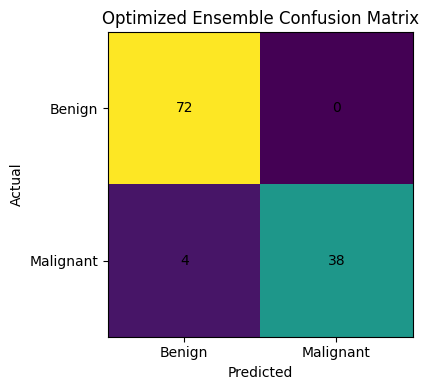


ADVERSARIAL ROBUSTNESS
       Model  Accuracy  Precision  Sensitivity  Specificity     F1  ROC_AUC  Epsilon  Accuracy_Drop_pp  ROC_AUC_Drop_pp
epsilon=0.00    0.9649     1.0000       0.9048       1.0000 0.9500   0.9983     0.00            0.0000           0.0000
epsilon=0.05    0.9561     1.0000       0.8810       1.0000 0.9367   0.9934     0.05            0.8772           0.4960
epsilon=0.10    0.9386     0.9730       0.8571       0.9861 0.9114   0.9815     0.10            2.6316           1.6865
epsilon=0.20    0.8684     0.8649       0.7619       0.9306 0.8101   0.9302     0.20            9.6491           6.8122
epsilon=0.30    0.7982     0.7436       0.6905       0.8611 0.7160   0.8439     0.30           16.6667          15.4431


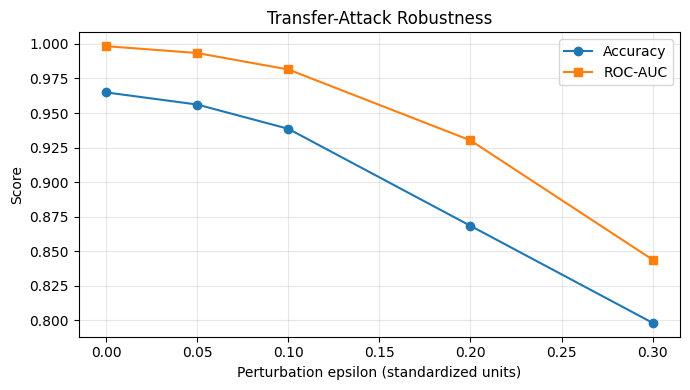

Computing SHAP: XGBoost


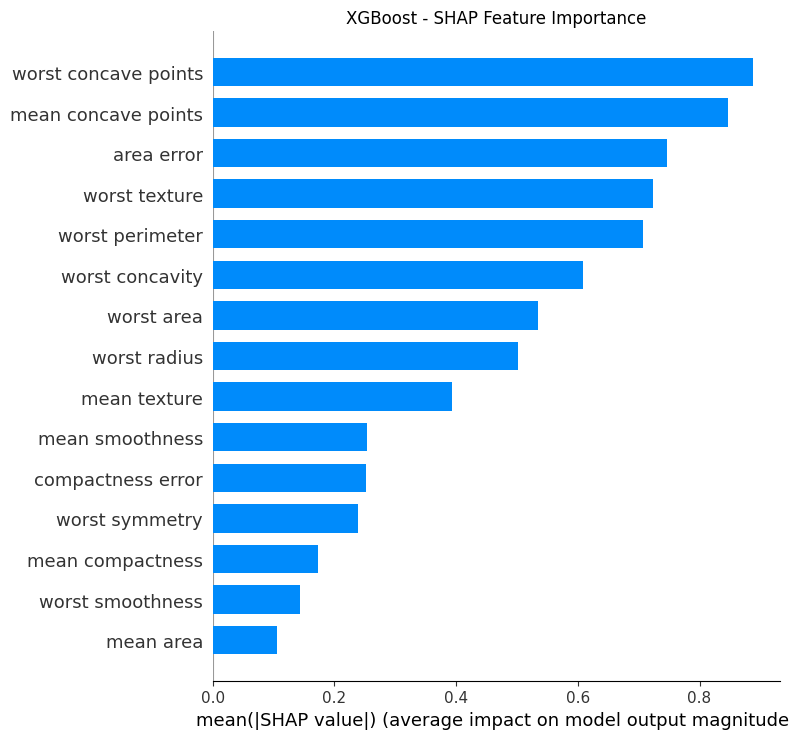

Computing SHAP: AdaBoost


PermutationExplainer explainer: 115it [00:57,  1.65it/s]
PermutationExplainer explainer: 115it [00:59,  1.61it/s]


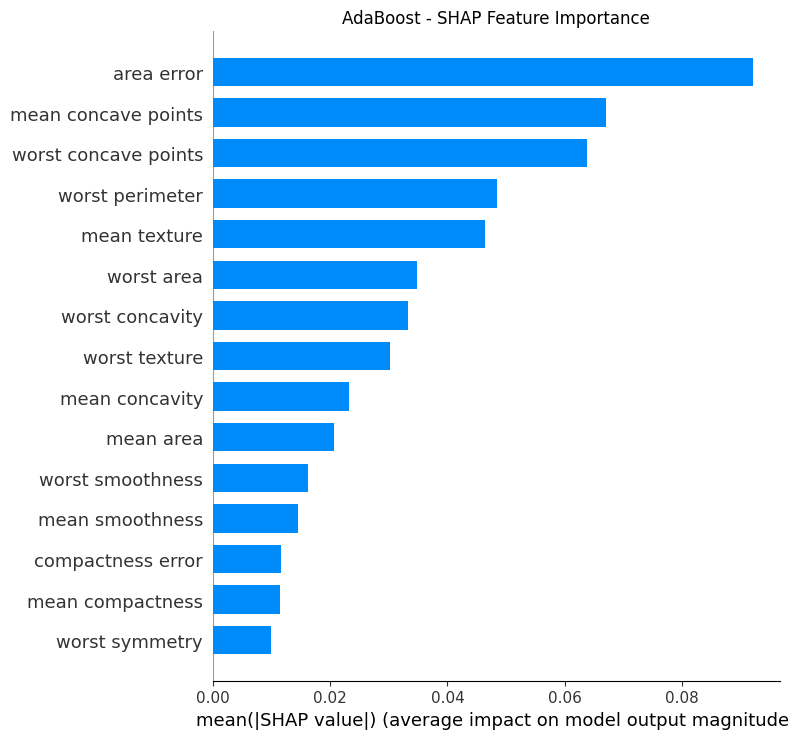

Computing SHAP: CatBoost


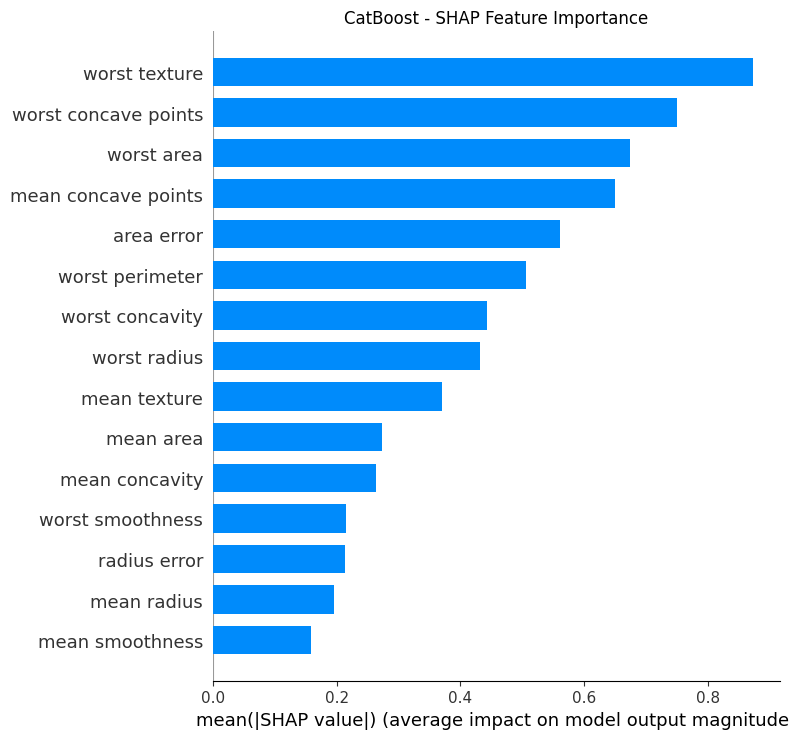


SHAP EXPLANATION STABILITY
   Model  SHAP_Rank_Correlation  Top10_Overlap
 XGBoost                 0.9982            0.9
AdaBoost                 0.9973            1.0
CatBoost                 0.9991            1.0

TOP 15 AGGREGATED FEATURES
             Feature  Weighted_SHAP_Importance
       worst texture                  0.829322
worst concave points                  0.752666
 mean concave points                  0.663622
          worst area                  0.637598
          area error                  0.575870
     worst perimeter                  0.523236
     worst concavity                  0.456943
        worst radius                  0.431473
        mean texture                  0.365387
           mean area                  0.242054
      mean concavity                  0.225465
    worst smoothness                  0.200120
        radius error                  0.186248
     mean smoothness                  0.168261
         mean radius                  0.166586

===

In [6]:
# =====================================================================
# RESEARCH PIPELINE: Reliability-Aware Boosting Ensemble for WDBC
# Models: XGBoost + AdaBoost + CatBoost
# Methods: OOF weight optimization, adversarial robustness, SHAP stability
# Environment: Google Colab
# =====================================================================

%pip -q install xgboost catboost shap

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.optimize import minimize
from scipy.stats import spearmanr

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, classification_report
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42
EPSILON_OPT = 0.10
EPSILON_TEST = [0.0, 0.05, 0.10, 0.20, 0.30]

# -------------------- 1. DATASET --------------------------------------

data = load_breast_cancer()
X = data.data
feature_names = np.array(data.feature_names)

# Positive class = malignant; negative class = benign
y = (data.target == 0).astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Dataset:", X.shape)
print("Training:", len(y_train), "| Test:", len(y_test))
print("Malignant:", int(y.sum()), "| Benign:", int((y == 0).sum()))

# -------------------- 2. MODEL DEFINITIONS ----------------------------

models = {
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        reg_lambda=1.0, eval_metric="logloss",
        random_state=SEED, n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, random_state=SEED),
        n_estimators=100, learning_rate=0.5, random_state=SEED
    ),
    "CatBoost": CatBoostClassifier(
        iterations=200, depth=5, learning_rate=0.05,
        loss_function="Logloss", verbose=0,
        random_seed=SEED, thread_count=2,
        allow_writing_files=False
    )
}

names = list(models.keys())
K = len(names)

# -------------------- 3. FGSM-STYLE SURROGATE ATTACK -----------------
# Logistic Regression supplies gradients; attacks are transferred to
# the tree models. Epsilon is measured in standardized feature units.

def make_attack(X_input, y_true, surrogate, epsilon):
    if epsilon == 0:
        return X_input.copy()

    p = np.clip(
        surrogate.predict_proba(X_input)[:, 1], 1e-7, 1 - 1e-7
    )
    grad = (
        (p - y_true)[:, None]
        * surrogate.coef_[0][None, :]
    )
    return X_input + epsilon * np.sign(grad)

# -------------------- 4. OOF PREDICTIONS FOR WEIGHT OPTIMIZATION ------
# Each validation fold is transformed using a scaler fitted only on
# that fold's training partition.
# Both clean and adversarial OOF probabilities are retained.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_clean = np.zeros((len(y_train), K))
oof_adv = np.zeros((len(y_train), K))

for fold, (itr, iva) in enumerate(cv.split(X_train_raw, y_train), 1):
    print(f"OOF fold {fold}/5")

    scaler_fold = StandardScaler()
    Xtr = scaler_fold.fit_transform(X_train_raw[itr])
    Xva = scaler_fold.transform(X_train_raw[iva])

    ytr, yva = y_train[itr], y_train[iva]

    surrogate_fold = LogisticRegression(max_iter=2000)
    surrogate_fold.fit(Xtr, ytr)
    Xva_adv = make_attack(Xva, yva, surrogate_fold, EPSILON_OPT)

    for j, name in enumerate(names):
        model = clone(models[name])
        model.fit(Xtr, ytr)

        oof_clean[iva, j] = model.predict_proba(Xva)[:, 1]
        oof_adv[iva, j] = model.predict_proba(Xva_adv)[:, 1]

# -------------------- 5. OPTIMIZED WEIGHTED ENSEMBLE ------------------
# Objective balances clean and attacked OOF log-loss.
# This is an experimental reliability-aware objective.
# SHAP stability is evaluated separately below.
# Weights are constrained to be nonnegative and sum to one.

def weighted_logloss(weights, probabilities, labels):
    p = np.clip(probabilities @ weights, 1e-7, 1 - 1e-7)
    return log_loss(labels, p, labels=[0, 1])

LAMBDA_CLEAN = 0.5
LAMBDA_ADV = 0.5

def objective(weights):
    clean_loss = weighted_logloss(weights, oof_clean, y_train)
    adv_loss = weighted_logloss(weights, oof_adv, y_train)
    return LAMBDA_CLEAN * clean_loss + LAMBDA_ADV * adv_loss

optimization = minimize(
    objective,
    x0=np.ones(K) / K,
    method="SLSQP",
    bounds=[(0, 1)] * K,
    constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
    options={"maxiter": 500, "ftol": 1e-10}
)

if not optimization.success:
    raise RuntimeError("Weight optimization failed: " + optimization.message)

weights = optimization.x
equal_weights = np.ones(K) / K

print("\nOptimized ensemble weights:")
for name, weight in zip(names, weights):
    print(f"{name}: {weight:.4f}")

print("OOF optimized objective:", round(optimization.fun, 5))
print("OOF equal-weight objective:",
      round(objective(equal_weights), 5))

# -------------------- 6. FINAL FIT ON TRAINING DATA -------------------

scaler = StandardScaler()
Xtr = scaler.fit_transform(X_train_raw)
Xte = scaler.transform(X_test_raw)

fitted_models = {}

for name in names:
    model = clone(models[name])
    model.fit(Xtr, y_train)
    fitted_models[name] = model

# Untouched test set: used only for final evaluation
test_clean = np.column_stack([
    fitted_models[n].predict_proba(Xte)[:, 1] for n in names
])

p_equal = test_clean @ equal_weights
p_optimized = test_clean @ weights

# -------------------- 7. METRICS --------------------------------------

def metrics(y_true, p, label):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    pred = (p >= 0.5).astype(int)

    return {
        "Model": label,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Sensitivity": recall_score(y_true, pred, zero_division=0),
        "Specificity": recall_score(
            y_true, pred, pos_label=0, zero_division=0
        ),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, p)
    }

rows = [
    metrics(y_test, test_clean[:, j], name)
    for j, name in enumerate(names)
]
rows.append(metrics(y_test, p_equal, "Equal-Weight Voting"))
rows.append(metrics(y_test, p_optimized, "Optimized Ensemble"))

print("\nCLEAN TEST RESULTS")
print(pd.DataFrame(rows).set_index("Model").round(4))

final_pred = (p_optimized >= 0.5).astype(int)

print("\nClassification report:")
print(classification_report(
    y_test, final_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

cm = confusion_matrix(y_test, final_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Optimized Ensemble Confusion Matrix")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

# -------------------- 8. ADVERSARIAL ROBUSTNESS -----------------------
# Transfer-based FGSM attack; not a white-box tree attack.
# Attack generation uses the held-out labels, so interpret this as
# a supervised adversarial stress test, not a deployment simulation.

surrogate = LogisticRegression(max_iter=2000)
surrogate.fit(Xtr, y_train)

robust_rows = []
robust_probabilities = {}

for eps in EPSILON_TEST:
    X_attack = make_attack(Xte, y_test, surrogate, eps)

    individual_p = np.column_stack([
        fitted_models[n].predict_proba(X_attack)[:, 1]
        for n in names
    ])

    p_attack = individual_p @ weights
    robust_probabilities[eps] = p_attack

    row = metrics(y_test, p_attack, f"epsilon={eps:.2f}")
    row["Epsilon"] = eps
    robust_rows.append(row)

robust_df = pd.DataFrame(robust_rows)

clean_acc = robust_df.loc[robust_df["Epsilon"] == 0, "Accuracy"].iloc[0]
clean_auc = robust_df.loc[robust_df["Epsilon"] == 0, "ROC_AUC"].iloc[0]

robust_df["Accuracy_Drop_pp"] = (
    clean_acc - robust_df["Accuracy"]
) * 100

robust_df["ROC_AUC_Drop_pp"] = (
    clean_auc - robust_df["ROC_AUC"]
) * 100

print("\nADVERSARIAL ROBUSTNESS")
print(robust_df.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(robust_df["Epsilon"], robust_df["Accuracy"],
         marker="o", label="Accuracy")
plt.plot(robust_df["Epsilon"], robust_df["ROC_AUC"],
         marker="s", label="ROC-AUC")
plt.xlabel("Perturbation epsilon (standardized units)")
plt.ylabel("Score")
plt.title("Transfer-Attack Robustness")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 9. SHAP EXPLAINABILITY --------------------------
# Compute per-model SHAP importance and explanation stability.
# For binary tree classifiers, select the positive-class SHAP values
# where the SHAP API returns class-specific values.

def positive_class_shap(model, X_values):
    # Fallback to model-agnostic Explainer if TreeExplainer doesn't support the ensemble
    try:
        explainer = shap.TreeExplainer(model)
        values = explainer.shap_values(X_values)
    except Exception:
        explainer = shap.Explainer(model.predict, X_values)
        values = explainer(X_values).values

    if isinstance(values, list):
        values = values[-1]

    values = np.asarray(values)

    if values.ndim == 3:
        values = values[:, :, 1] if values.shape[-1] == 2 else values[:, :, 0]

    return values

shap_clean = {}
shap_perturbed = {}
X_shap_adv = Xte + np.random.default_rng(SEED).normal(
    0, 0.10, size=Xte.shape
)

importance_rows = []

for name, model in fitted_models.items():
    print("Computing SHAP:", name)

    sv_clean = positive_class_shap(model, Xte)
    sv_pert = positive_class_shap(model, X_shap_adv)

    shap_clean[name] = sv_clean
    shap_perturbed[name] = sv_pert

    imp_clean = np.abs(sv_clean).mean(axis=0)
    imp_pert = np.abs(sv_pert).mean(axis=0)

    rho = spearmanr(imp_clean, imp_pert).statistic

    k = 10
    top_clean = set(np.argsort(imp_clean)[-k:])
    top_pert = set(np.argsort(imp_pert)[-k:])
    topk_overlap = len(top_clean & top_pert) / k

    importance_rows.append({
        "Model": name,
        "SHAP_Rank_Correlation": rho,
        "Top10_Overlap": topk_overlap
    })

    shap.summary_plot(
        sv_clean, Xte,
        feature_names=feature_names,
        plot_type="bar",
        max_display=15,
        show=False
    )
    plt.title(f"{name} - SHAP Feature Importance")
    plt.tight_layout()
    plt.show()

stability_df = pd.DataFrame(importance_rows)

print("\nSHAP EXPLANATION STABILITY")
print(stability_df.round(4).to_string(index=False))

# Aggregate global importance across the three models
all_importances = []

for name in names:
    all_importances.append(
        np.abs(shap_clean[name]).mean(axis=0)
    )

aggregate_importance = np.average(
    np.vstack(all_importances),
    axis=0,
    weights=weights
)

shap_ranking = pd.DataFrame({
    "Feature": feature_names,
    "Weighted_SHAP_Importance": aggregate_importance
}).sort_values("Weighted_SHAP_Importance", ascending=False)

print("\nTOP 15 AGGREGATED FEATURES")
print(shap_ranking.head(15).to_string(index=False))

# -------------------- 10. SUMMARY -------------------------------------

print("\n================ RESEARCH SUMMARY ================")
print("Optimized weights:", dict(zip(names, weights.round(4))))
print("Clean test ROC-AUC:", round(
    roc_auc_score(y_test, p_optimized), 4
))
print("Clean test sensitivity:", round(
    recall_score(y_test, final_pred, zero_division=0), 4
))
print("Clean test specificity:", round(
    recall_score(y_test, final_pred, pos_label=0, zero_division=0), 4
))
print("Mean SHAP rank correlation:", round(
    stability_df["SHAP_Rank_Correlation"].mean(), 4
))
print("Mean top-10 SHAP overlap:", round(
    stability_df["Top10_Overlap"].mean(), 4
))

print("""
IMPORTANT:
1. The test set must not be used to choose weights or hyperparameters.
2. The weight objective balances clean and attacked OOF log-loss;
   SHAP stability is measured separately, not optimized directly.
3. The attack is a Logistic Regression transfer-based stress test.
4. WDBC is small; use nested/repeated cross-validation and external
   validation before claiming statistically reliable superiority.
5. This is research experimentation, not a clinically validated tool.
""")

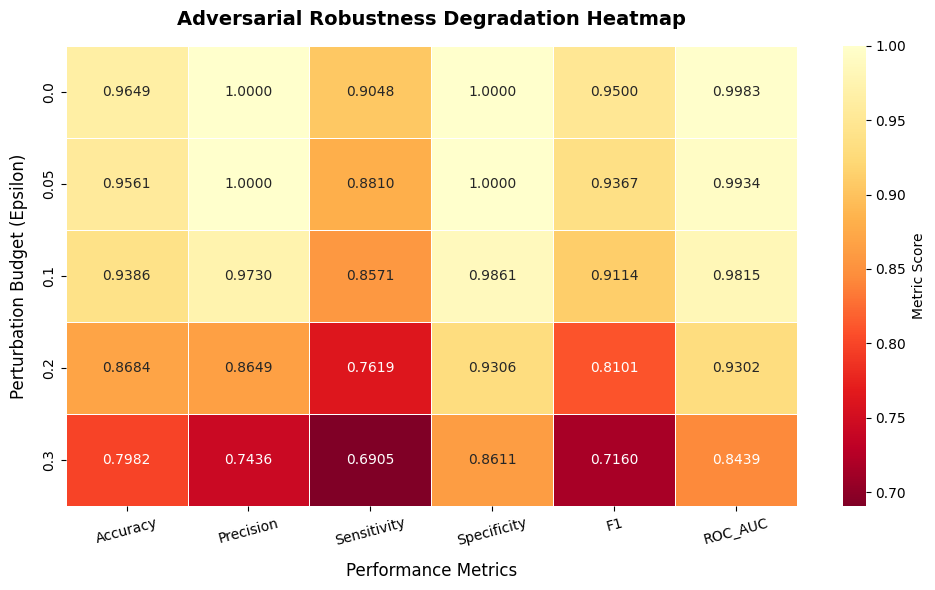

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the data for the heatmap
# We will use Epsilon as the index and plot the key performance metrics
heatmap_data = robust_df.set_index("Epsilon")[["Accuracy", "Precision", "Sensitivity", "Specificity", "F1", "ROC_AUC"]]

# Plotting the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlOrRd_r",
    linewidths=0.5,
    cbar_kws={"label": "Metric Score"}
)

plt.title("Adversarial Robustness Degradation Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Performance Metrics", fontsize=12, labelpad=10)
plt.ylabel("Perturbation Budget (Epsilon)", fontsize=12, labelpad=10)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

TOP UNSTABLE FEATURES (SHAP INSTABILITY):
             Feature  Instability
          area error     0.098237
          worst area     0.093777
       worst texture     0.084787
 mean concave points     0.080875
        worst radius     0.063601
     worst concavity     0.063191
worst concave points     0.050935
           mean area     0.045984
     worst perimeter     0.044950
        mean texture     0.041142

Retraining models by masking the 5 most unstable features...

--- RETRAINED ENSEMBLE ROBUSTNESS (SHAP-GUIDED) ---
 Epsilon  Accuracy  Precision  Sensitivity  Specificity     F1  ROC_AUC
    0.00    0.9737     1.0000       0.9286       1.0000 0.9630   0.9967
    0.05    0.9474     0.9737       0.8810       0.9861 0.9250   0.9904
    0.10    0.9298     0.9474       0.8571       0.9722 0.9000   0.9808
    0.20    0.8860     0.8537       0.8333       0.9167 0.8434   0.9375
    0.30    0.8421     0.8000       0.7619       0.8889 0.7805   0.8519


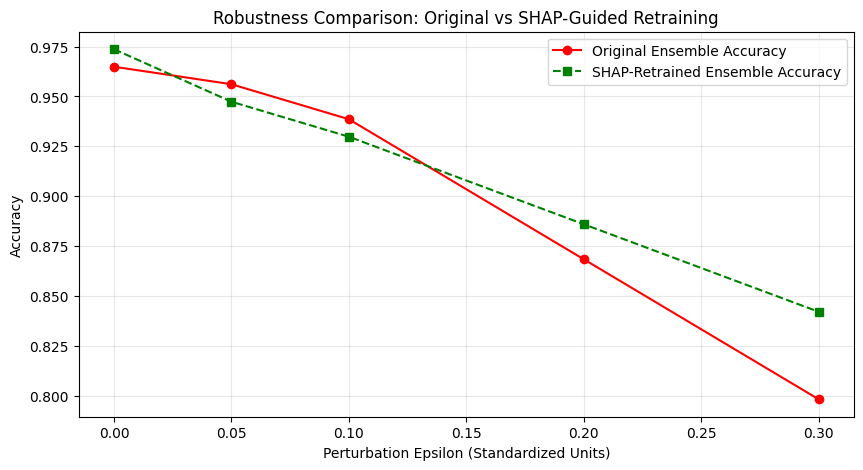

In [8]:
# =====================================================================
# SHAP-GUIDED RETRAINING FOR ADVERSARIAL ROBUSTNESS
# =====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

# 1. Calculate Feature Instability from SHAP values
# Instability is defined as the mean absolute difference in SHAP values between clean and perturbed states
instabilities = []
for name in names:
    diff = np.abs(shap_clean[name] - shap_perturbed[name]).mean(axis=0)
    instabilities.append(diff)

# Average instability across models weighted by ensemble weights
mean_instability = np.average(np.vstack(instabilities), axis=0, weights=weights)

# Rank features by instability
instability_df = pd.DataFrame({
    "Feature": feature_names,
    "Instability": mean_instability
}).sort_values("Instability", ascending=False)

print("TOP UNSTABLE FEATURES (SHAP INSTABILITY):")
print(instability_df.head(10).to_string(index=False))

# 2. Select Unstable Features to Mask (e.g., Top 5 most unstable)
N_MASK = 5
unstable_indices = instability_df.head(N_MASK).index.values

# Create robust training and testing sets with unstable features masked (set to 0)
Xtr_robust = Xtr.copy()
Xte_robust = Xte.copy()

Xtr_robust[:, unstable_indices] = 0
Xte_robust[:, unstable_indices] = 0

print(f"\nRetraining models by masking the {N_MASK} most unstable features...")

# 3. Retrain Models on Robust Feature Space
robust_fitted_models = {}
for name in names:
    model = clone(models[name])
    model.fit(Xtr_robust, y_train)
    robust_fitted_models[name] = model

# 4. Evaluate Robustness of the New Ensemble under Adversarial Attack
robust_test_clean = np.column_stack([
    robust_fitted_models[n].predict_proba(Xte_robust)[:, 1] for n in names
])
p_robust_opt = robust_test_clean @ weights

# Run the stress test on retrained model
retrained_robust_rows = []
for eps in EPSILON_TEST:
    # Generate attack on the robust feature space
    X_attack_robust = make_attack(Xte_robust, y_test, surrogate, eps)

    individual_p_robust = np.column_stack([
        robust_fitted_models[n].predict_proba(X_attack_robust)[:, 1]
        for n in names
    ])

    p_attack_robust = individual_p_robust @ weights
    row = metrics(y_test, p_attack_robust, f"epsilon={eps:.2f}")
    row["Epsilon"] = eps
    retrained_robust_rows.append(row)

retrained_robust_df = pd.DataFrame(retrained_robust_rows)

# Compare Original vs Retrained Ensemble Robustness
print("\n--- RETRAINED ENSEMBLE ROBUSTNESS (SHAP-GUIDED) ---")
print(retrained_robust_df[["Epsilon", "Accuracy", "Precision", "Sensitivity", "Specificity", "F1", "ROC_AUC"]].round(4).to_string(index=False))

# Plot comparison
plt.figure(figsize=(10, 5))
plt.plot(robust_df["Epsilon"], robust_df["Accuracy"], 'o-', label="Original Ensemble Accuracy", color="red")
plt.plot(retrained_robust_df["Epsilon"], retrained_robust_df["Accuracy"], 's--', label="SHAP-Retrained Ensemble Accuracy", color="green")
plt.xlabel("Perturbation Epsilon (Standardized Units)")
plt.ylabel("Accuracy")
plt.title("Robustness Comparison: Original vs SHAP-Guided Retraining")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()